# PathSnap — Dataset Exploration (EDA)
**UE24CS352A Machine Learning | PathSnap: Distributed Map-Matching & Route Reconstruction**

This notebook investigates the supplied trip dataset before model training. It covers file inventory, GPS quality, timestamps, trajectory statistics, geographic extent, road-network topology, reference route checks, and Folium visualizations.

**Partitions:** 80 training trips, 10 student-testing trips (expected). The 10 reserved evaluator-testing trips must **not** be used for development. This notebook never uses evaluator data. Results and conclusions must be based on the actual outputs you obtain.

**Important:** `.track` has longitude, latitude, timestamp; `.nodes` has longitude, latitude; `.arcs` has directed from/to node IDs; `.route` contains a chronological sequence of reference arc IDs. Row indices define node IDs and arc IDs. Reference route entries are **not** per-GPS-observation labels.

## 1. Setup and dataset discovery
Run the installation cell only if dependencies are missing. The loader accepts either an extracted `Student folder/` or the original `Student folder.zip` in the notebook directory; it also supports a custom path.

In [3]:
# Uncomment in a fresh Jupyter/Colab environment if necessary:
# %pip install pandas numpy matplotlib networkx folium pyproj

from pathlib import Path
import zipfile
import tempfile
import shutil
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import folium
from pyproj import Geod
from IPython.display import display

pd.set_option('display.max_columns', 30)
GEOD = Geod(ellps='WGS84')
OUTPUT_DIR = Path('eda_outputs')
OUTPUT_DIR.mkdir(exist_ok=True)
print('Libraries ready.')

Libraries ready.


In [4]:
import tempfile
import zipfile
from pathlib import Path

# Let's target '/content/Student folder.zip' explicitly or auto-discover
DATA_SOURCE = Path('/content/Student folder.zip')

if not DATA_SOURCE.exists():
    DATA_SOURCE = Path('Student folder.zip')

if DATA_SOURCE.exists():
    extract_root = Path('/content/extracted_student_folder')
    extract_root.mkdir(parents=True, exist_ok=True)
    try:
        with zipfile.ZipFile(DATA_SOURCE) as archive:
            archive.extractall(extract_root)
        print('Successfully extracted ZIP to:', extract_root)
        search_root = extract_root
    except zipfile.BadZipFile:
        print('Warning: ZIP file is corrupted or not a zip file. Checking if directory already exists.')
        search_root = Path('Student folder')
else:
    search_root = Path('Student folder')

possible_roots = [
    search_root,
    search_root / 'Student folder',
    Path('/content/Student folder'),
    Path('/content/extracted_student_folder/Student folder')
]

DATA_DIR = next((p for p in possible_roots if p.exists() and (p/'train').is_dir() and (p/'student_test').is_dir()), None)

if DATA_DIR is None:
    # If not found, let's list directory contents to debug
    import os
    print('Directory contents of search_root:', list(search_root.glob('*')) if search_root.exists() else 'Does not exist')
    raise FileNotFoundError('Could not find train/ and student_test/ directories.')

TRAIN_DIR, STUDENT_TEST_DIR = DATA_DIR/'train', DATA_DIR/'student_test'
print('Dataset root verified:', DATA_DIR)

Dataset root verified: Student folder


In [5]:
import os
from pathlib import Path

print('Current working directory:', os.getcwd())
print('\nDirectory contents:')
for p in sorted(Path('.').iterdir()):
    suffix = ' (dir)' if p.is_dir() else f' ({p.stat().st_size / 1024:.2f} KB)'
    print(f'- {p.name}{suffix}')

Current working directory: c:\Users\sanja\Desktop\PESU\sem-5\ML\hackathon

Directory contents:
- Assessment and Plagiarism Policy.pdf (121.74 KB)
- Dataset Exploration.pdf (177.86 KB)
- Deliverables.pdf (188.28 KB)
- eda_outputs (dir)
- Main Guidelines.pdf (195.40 KB)
- Models and Training Guidelines.pdf (168.19 KB)
- PathSnap_Data_Exploration (1).ipynb (444.57 KB)
- Student folder (dir)


## 2. Dataset inventory and raw file format

,partition,trip_count,expected
0,train,80,80
1,student_test,10,10


Partition IDs overlap: False


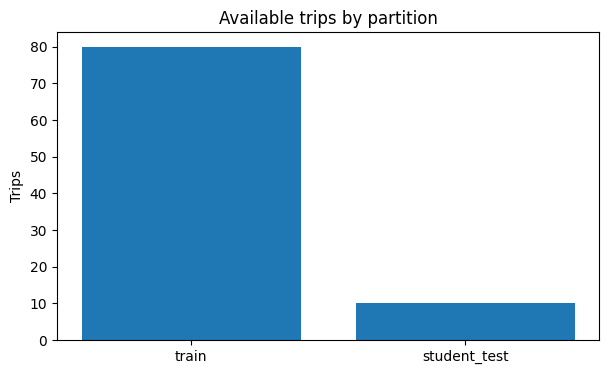

In [6]:
train_trips = sorted(p for p in TRAIN_DIR.iterdir() if p.is_dir())
test_trips = sorted(p for p in STUDENT_TEST_DIR.iterdir() if p.is_dir())
partition_table = pd.DataFrame([
    {'partition':'train', 'trip_count':len(train_trips), 'expected':80},
    {'partition':'student_test', 'trip_count':len(test_trips), 'expected':10}
])
display(partition_table)
print('Partition IDs overlap:', bool({p.name for p in train_trips} & {p.name for p in test_trips}))
assert train_trips, 'No training trips found'
plt.figure(figsize=(7,4))
plt.bar(partition_table.partition, partition_table.trip_count)
plt.title('Available trips by partition'); plt.ylabel('Trips'); plt.show()

In [7]:
EXTENSIONS = ['track','nodes','arcs','route']
def inventory(partition, folders):
    rows = []
    for folder in folders:
        row = {'partition':partition, 'trip_id':folder.name}
        for ext in EXTENSIONS:
            path = folder / f'{folder.name}.{ext}'
            row[f'{ext}_exists'] = path.is_file()
            row[f'{ext}_kb'] = path.stat().st_size/1024 if path.is_file() else np.nan
        rows.append(row)
    return pd.DataFrame(rows)

file_inventory = pd.concat([
    inventory('train',train_trips),inventory('student_test',test_trips)
],ignore_index=True)
display(file_inventory.head())
missing = file_inventory.loc[~file_inventory[[f'{e}_exists' for e in EXTENSIONS]].all(axis=1)]
print('Trips with missing files:',len(missing)); display(missing)
display(file_inventory[[f'{e}_kb' for e in EXTENSIONS]].describe())
file_inventory.to_csv(OUTPUT_DIR/'file_inventory.csv',index=False)

,partition,trip_id,track_exists,track_kb,nodes_exists,nodes_kb,arcs_exists,arcs_kb,route_exists,route_kb
0,train,00000001,True,40.014648,True,1647.823242,True,1902.806641,True,3.045898
1,train,00000002,True,232.504883,True,155.000000,True,152.850586,True,1.365234
2,train,00000003,True,25.550781,True,178.476562,True,171.614258,True,0.401367
3,train,00000004,True,34.162109,True,143.554688,True,146.228516,True,1.544922
4,train,00000005,True,32.595703,True,17.539062,True,12.061523,True,0.411133


Trips with missing files: 0


,partition,trip_id,track_exists,track_kb,nodes_exists,nodes_kb,arcs_exists,arcs_kb,route_exists,route_kb


,track_kb,nodes_kb,arcs_kb,route_kb
count,90.000000,90.000000,90.000000,90.000000
mean,81.361361,436.781966,500.975564,1.997027
std,103.636430,589.127383,735.813861,1.964983
min,8.083984,5.547852,4.589844,0.247070
25%,28.158691,71.391602,66.592041,0.794434
50%,47.371094,183.056641,178.758301,1.361328
75%,89.696045,515.365723,575.237305,2.472900
max,611.749023,2876.032227,3766.566406,11.836914


In [8]:
def load_trip(folder):
    folder = Path(folder); tid = folder.name
    spec = {
        'track':['longitude','latitude','timestamp'],
        'nodes':['longitude','latitude'],
        'arcs':['from_node_id','to_node_id'],
        'route':['arc_id']
    }
    data = {}
    for ext, names in spec.items():
        data[ext] = pd.read_csv(folder/f'{tid}.{ext}', sep=r'\s+', header=None, names=names)
    return data

sample_folder = train_trips[0]
sample = load_trip(sample_folder)
print('Sample trip:',sample_folder.name)
for ext, df in sample.items():
    print(f'\n{ext}: shape={df.shape}, types={df.dtypes.to_dict()}')
    display(df.head())

Sample trip: 00000001

track: shape=(1315, 3), types={'longitude': dtype('float64'), 'latitude': dtype('float64'), 'timestamp': dtype('float64')}


,longitude,latitude,timestamp
0,8.595203,49.844053,1.0
1,8.595294,49.844441,2.0
2,8.595352,49.844883,3.0
3,8.595390,49.845379,4.0
4,8.595587,49.845750,5.0



nodes: shape=(88809, 2), types={'longitude': dtype('float64'), 'latitude': dtype('float64')}


,longitude,latitude
0,8.581679,49.857880
1,8.584637,49.858295
2,8.580173,49.858567
3,8.584392,49.859119
4,8.584935,49.857396



arcs: shape=(165790, 2), types={'from_node_id': dtype('int64'), 'to_node_id': dtype('int64')}


,from_node_id,to_node_id
0,0,281
1,0,1
2,0,5
3,1,0
4,1,40750



route: shape=(525, 1), types={'arc_id': dtype('int64')}


,arc_id
0,2641
1,64973
2,133948
3,133949
4,139208


## 3. GPS observations, quality, and time sampling

In [9]:
track = sample['track'].copy()
print('Observations:',len(track))
display(track.describe(include='all'))
print('Missing by column:'); display(track.isna().sum().to_frame('missing'))
valid_coords = (track.longitude.between(-180,180) & track.latitude.between(-90,90) &
                np.isfinite(track.longitude) & np.isfinite(track.latitude))
print('Invalid GPS coordinates:',int((~valid_coords).sum()))
print('Duplicate full GPS rows:',int(track.duplicated().sum()))
track['dt_seconds'] = track.timestamp.diff()
print('Nonpositive timestamp intervals:',int((track.dt_seconds<=0).sum()))
print('One-second interval fraction:',round(float((track.dt_seconds==1).mean()),4))
print('Gaps > 3 seconds:',int((track.dt_seconds>3).sum()))
display(track.dt_seconds.describe())

Observations: 1315


,longitude,latitude,timestamp
count,1315.000000,1315.000000,1315.000000
mean,8.605599,50.088368,661.000760
std,0.016356,0.117561,384.387699
min,8.570524,49.844053,1.000000
25%,8.596061,49.987136,329.500000
50%,8.603564,50.128292,658.000000
75%,8.612624,50.199064,988.500000
max,8.647860,50.211882,1358.000000


Missing by column:


,missing
longitude,0
latitude,0
timestamp,0


Invalid GPS coordinates: 0
Duplicate full GPS rows: 0
Nonpositive timestamp intervals: 0
One-second interval fraction: 0.9802
Gaps > 3 seconds: 2


count    1314.000000
mean        1.032725
std         0.446355
min         1.000000
25%         1.000000
50%         1.000000
75%         1.000000
max        16.000000
Name: dt_seconds, dtype: float64

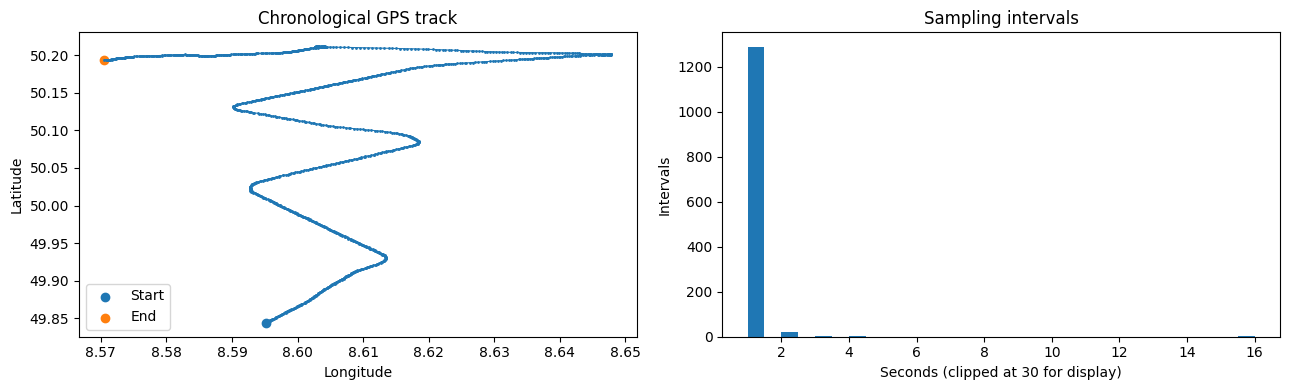

In [10]:
fig, axes = plt.subplots(1,2,figsize=(13,4))
axes[0].plot(track.longitude,track.latitude,linewidth=.8,marker='.',markersize=2)
axes[0].scatter(track.longitude.iloc[0],track.latitude.iloc[0],label='Start')
axes[0].scatter(track.longitude.iloc[-1],track.latitude.iloc[-1],label='End')
axes[0].set(xlabel='Longitude',ylabel='Latitude',title='Chronological GPS track')
axes[0].legend()
axes[1].hist(track.dt_seconds.dropna().clip(upper=30),bins=30)
axes[1].set(xlabel='Seconds (clipped at 30 for display)',ylabel='Intervals',title='Sampling intervals')
plt.tight_layout(); plt.savefig(OUTPUT_DIR/'sample_gps_and_intervals.png',dpi=150); plt.show()

,timestamp,dt_seconds,step_distance_m,speed_kmh
0,1.0,NaN,NaN,NaN
1,2.0,1.0,43.649253,157.137310
2,3.0,1.0,49.338606,177.618980
3,4.0,1.0,55.235798,198.848872
4,5.0,1.0,43.629783,157.067219
5,6.0,1.0,46.438352,167.178067
6,7.0,1.0,46.308116,166.709216
7,8.0,1.0,40.716443,146.579195
8,9.0,1.0,50.364722,181.313000
9,10.0,1.0,34.543126,124.355252


,step_distance_m,speed_kmh
count,1314.000000,1314.000000
mean,38.225689,136.990304
std,15.462977,56.613892
min,1.802495,4.445139
25%,25.793925,91.917663
50%,41.381319,148.972750
75%,50.390276,181.404992
max,72.444519,260.800267


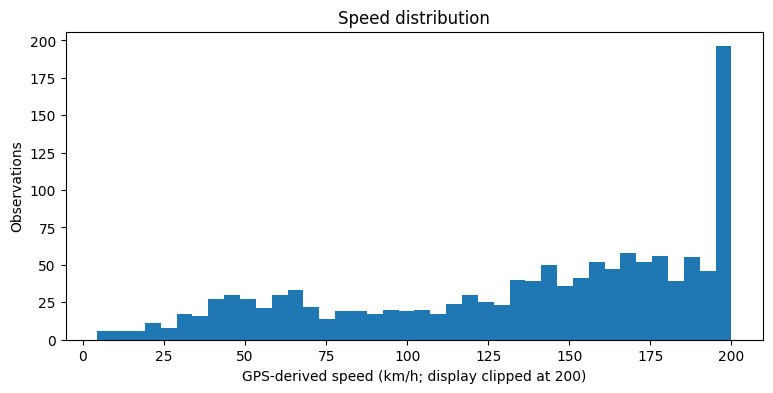

Note: speed spikes may reflect GPS noise rather than true vehicle speed.


In [11]:
# GPS-derived movement distance/speed, calculated geodesically (metres, not degrees)
lon1,lat1 = track.longitude.to_numpy()[:-1],track.latitude.to_numpy()[:-1]
lon2,lat2 = track.longitude.to_numpy()[1:],track.latitude.to_numpy()[1:]
_,_,metres = GEOD.inv(lon1,lat1,lon2,lat2)
track['step_distance_m'] = np.r_[np.nan,metres]
track['speed_kmh'] = np.where(track.dt_seconds>0,track.step_distance_m/track.dt_seconds*3.6,np.nan)
display(track[['timestamp','dt_seconds','step_distance_m','speed_kmh']].head(12))
display(track[['step_distance_m','speed_kmh']].describe())
fig, ax = plt.subplots(figsize=(9,4))
ax.hist(track.speed_kmh.replace([np.inf,-np.inf],np.nan).dropna().clip(upper=200),bins=40)
ax.set(xlabel='GPS-derived speed (km/h; display clipped at 200)',ylabel='Observations',title='Speed distribution')
plt.show()
print('Note: speed spikes may reflect GPS noise rather than true vehicle speed.')

## 4. All-trip summary
All statistics are computed independently per trip. We do **not** concatenate different trips into one continuous trajectory.

In [12]:
def summarize_trip(folder, partition):
    data=load_trip(folder)
    tr, nd, ar, rt=(data[k] for k in ['track','nodes','arcs','route'])
    dt=tr.timestamp.diff()
    valid = tr.longitude.between(-180,180) & tr.latitude.between(-90,90)
    return dict(partition=partition,trip_id=folder.name,
        gps_count=len(tr),node_count=len(nd),arc_count=len(ar),route_arc_count=len(rt),
        missing_gps_rows=int(tr.isna().any(axis=1).sum()),
        invalid_gps_rows=int((~valid).sum()),duplicate_gps_rows=int(tr.duplicated().sum()),
        nonpositive_time_gaps=int((dt<=0).sum()),large_gaps_gt3s=int((dt>3).sum()),
        one_second_pct=100*float((dt==1).sum()/dt.notna().sum()) if dt.notna().any() else np.nan,
        max_gap_s=dt.max(),
        min_lon=tr.longitude.min(),max_lon=tr.longitude.max(),
        min_lat=tr.latitude.min(),max_lat=tr.latitude.max())

rows=[]
for partition,folders in [('train',train_trips),('student_test',test_trips)]:
    for i,folder in enumerate(folders,1):
        try: rows.append(summarize_trip(folder,partition))
        except Exception as exc: print('Could not read:',folder,repr(exc))
trip_summary=pd.DataFrame(rows)
display(trip_summary.head())
display(trip_summary.groupby('partition')[['gps_count','node_count','arc_count','route_arc_count','large_gaps_gt3s']].agg(['count','mean','median','min','max']))
trip_summary.to_csv(OUTPUT_DIR/'trip_summary.csv',index=False)

,partition,trip_id,gps_count,node_count,arc_count,route_arc_count,missing_gps_rows,invalid_gps_rows,duplicate_gps_rows,nonpositive_time_gaps,large_gaps_gt3s,one_second_pct,max_gap_s,min_lon,max_lon,min_lat,max_lat
0,train,00000001,1315,88809,165790,525,0,0,0,0,2,98.097412,16.0,8.570524,8.647860,49.844053,50.211882
1,train,00000002,7243,7936,16139,262,0,0,0,0,97,97.445457,160.0,10.999961,11.050902,47.658344,47.695459
2,train,00000003,821,9138,18028,79,0,0,0,0,0,99.634146,2.0,37.154202,37.201595,55.977135,56.007585
3,train,00000004,1064,7350,15499,320,0,0,0,0,389,53.809972,51.0,12.342280,12.459615,52.590308,52.718960
4,train,00000005,1045,898,1579,105,0,0,0,0,0,100.000000,1.0,35.485577,35.544315,49.357581,49.613085


gps_count                                node_count              \
                 count       mean  median  min    max      count        mean   
partition                                                                      
student_test        10  1916.0000  1420.0  262   3958         10   9068.9000   
train               80  2605.2125  1529.0  361  19313         80  24168.5625   

                                   arc_count                                  \
              median   min     max     count     mean   median   min     max   
partition                                                                      
student_test  6596.5  1770   26635        10  18504.1  13145.0  3577   56027   
train         9608.0   299  155003        80  48461.3  19526.5   649  307392   

             route_arc_count                         large_gaps_gt3s           \
                       count   mean median min   max           count     mean   
partition                                                                       
student_test              10  347.7  250.0  95  1323              10   7.6000   
train                     80  391.7  280.0  59  2266              80  23.4375   

                              
             median min  max  
partition                     
student_test    0.0   0   69  
train           2.0   0  389

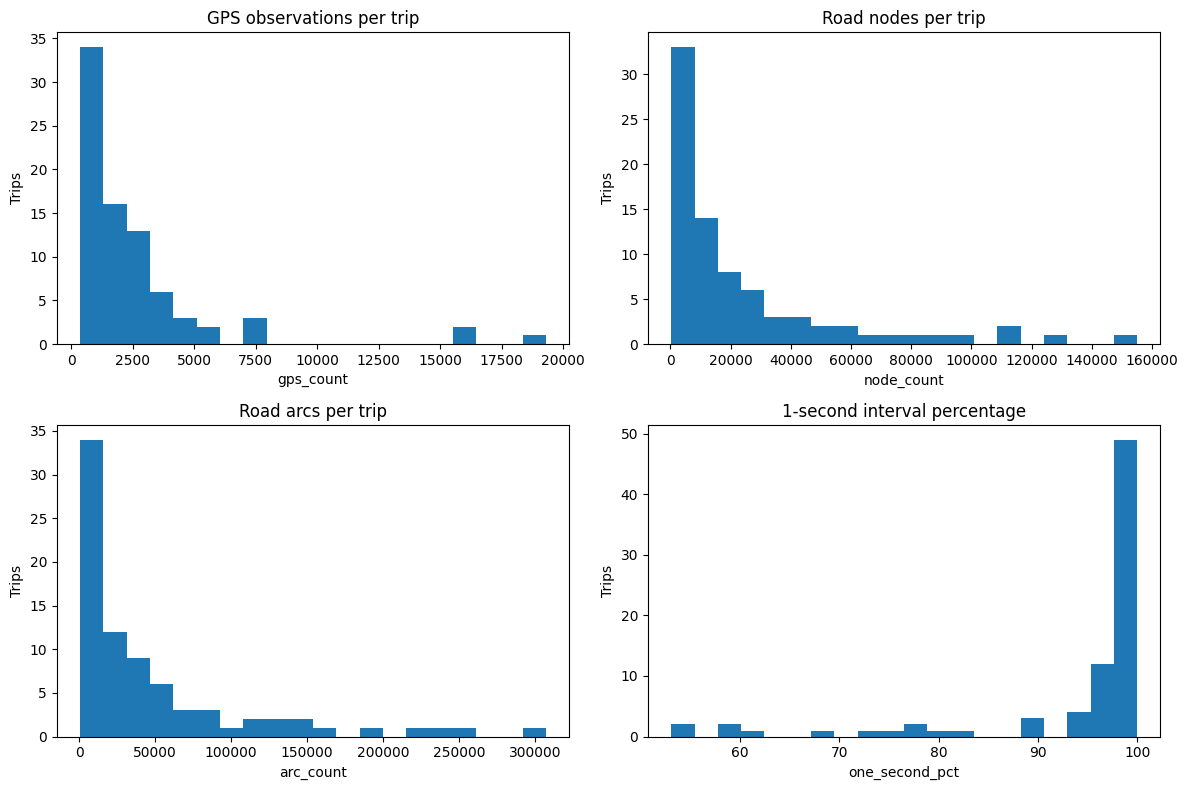

Trips with largest gaps:


,trip_id,gps_count,max_gap_s,large_gaps_gt3s
72,00000090,536,153064.0,39
61,00000078,2909,52810.0,264
55,00000069,2067,2658.0,2
16,00000021,15783,2161.0,2
8,00000011,2828,909.0,1
34,00000042,7739,670.0,52
64,00000081,3224,536.0,223
18,00000024,801,458.0,4
36,00000044,546,341.0,3
67,00000084,16031,312.0,5


Trips with fewest observations:


,trip_id,gps_count
20,00000026,361
32,00000039,363
13,00000018,379
11,00000014,448
17,00000022,474
41,00000050,518
72,00000090,536
36,00000044,546
47,00000058,599
37,00000045,640


In [13]:
training = trip_summary.query("partition == 'train'")
fig,axs=plt.subplots(2,2,figsize=(12,8))
for ax,col,title in zip(axs.flat,
    ['gps_count','node_count','arc_count','one_second_pct'],
    ['GPS observations per trip','Road nodes per trip','Road arcs per trip','1-second interval percentage']):
    ax.hist(training[col].dropna(),bins=20)
    ax.set(title=title,xlabel=col,ylabel='Trips')
plt.tight_layout(); plt.savefig(OUTPUT_DIR/'training_distributions.png',dpi=150); plt.show()
print('Trips with largest gaps:'); display(training.nlargest(10,'max_gap_s')[['trip_id','gps_count','max_gap_s','large_gaps_gt3s']])
print('Trips with fewest observations:'); display(training.nsmallest(10,'gps_count')[['trip_id','gps_count']])

## 5. Road network validity and connectivity
Arcs are **directed**. We preserve arc row indices as IDs. Connectivity summaries below are for the selected sample trip; running graph algorithms on all large networks may be expensive.

In [14]:
nodes, arcs, route = sample['nodes'],sample['arcs'],sample['route']
valid_edges=(arcs.from_node_id.between(0,len(nodes)-1) & arcs.to_node_id.between(0,len(nodes)-1))
print('Nodes:',len(nodes),'Arcs:',len(arcs))
print('Invalid node references in arcs:',int((~valid_edges).sum()))
print('Self-loops:',int((arcs.from_node_id==arcs.to_node_id).sum()))
print('Duplicate directed endpoint pairs:',int(arcs.duplicated().sum()))
G=nx.DiGraph()
G.add_nodes_from(range(len(nodes)))
G.add_edges_from(arcs.loc[valid_edges,['from_node_id','to_node_id']].itertuples(index=False,name=None))
print('Unique directed edges in graph:',G.number_of_edges())
print('Isolated nodes:',nx.number_of_isolates(G))
weak=list(nx.weakly_connected_components(G))
print('Weakly connected components:',len(weak))
print('Largest weak component:',max(map(len,weak),default=0))
# Strong connectivity can be slower on very large networks; run on the selected trip only.
strong_sizes=sorted((len(c) for c in nx.strongly_connected_components(G)),reverse=True)
print('Strongly connected components:',len(strong_sizes))
print('Largest strong component:',strong_sizes[0] if strong_sizes else 0)

Nodes: 88809 Arcs: 165790
Invalid node references in arcs: 0
Self-loops: 0
Duplicate directed endpoint pairs: 292
Unique directed edges in graph: 165498
Isolated nodes: 0
Weakly connected components: 175
Largest weak component: 86854
Strongly connected components: 1942
Largest strong component: 84999


,in_degree,out_degree
count,88809.000000,88809.000000
mean,1.863527,1.863527
std,0.740066,0.740310
min,0.000000,0.000000
25%,1.000000,1.000000
50%,2.000000,2.000000
75%,2.000000,2.000000
max,6.000000,6.000000


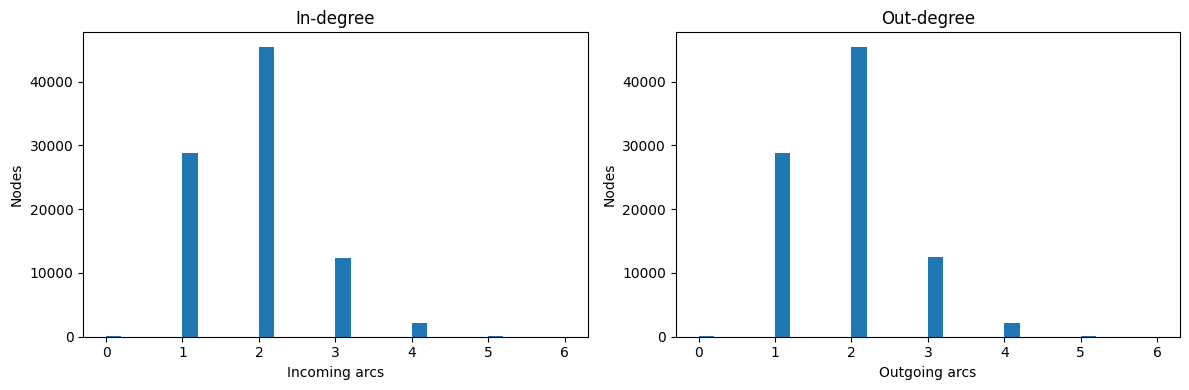

In [15]:
degree=pd.DataFrame({'in_degree':[G.in_degree(i) for i in range(len(nodes))],
                     'out_degree':[G.out_degree(i) for i in range(len(nodes))]})
display(degree.describe())
fig,axs=plt.subplots(1,2,figsize=(12,4))
axs[0].hist(degree.in_degree,bins=30); axs[0].set(title='In-degree',xlabel='Incoming arcs',ylabel='Nodes')
axs[1].hist(degree.out_degree,bins=30); axs[1].set(title='Out-degree',xlabel='Outgoing arcs',ylabel='Nodes')
plt.tight_layout(); plt.show()

count    165790.000000
mean         39.696705
std          55.457861
min           0.000000
25%           9.284658
50%          20.234830
75%          46.843615
max        1107.168686
Name: length_m, dtype: float64

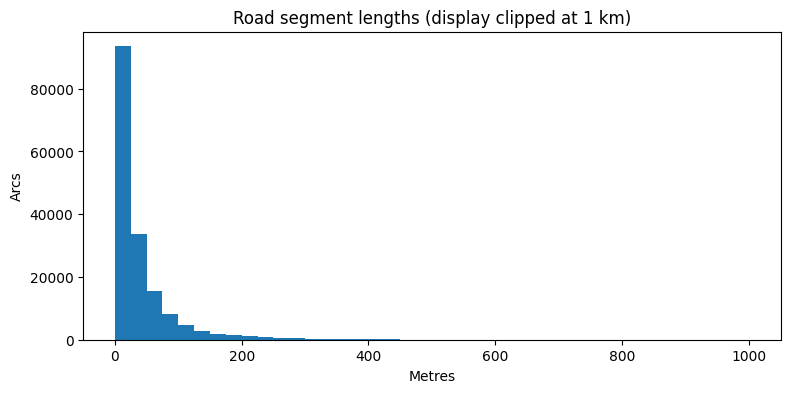

In [16]:
# Geodesic length for each valid directed road segment
edge=arcs.loc[valid_edges]
u=edge.from_node_id.to_numpy(dtype=int)
v=edge.to_node_id.to_numpy(dtype=int)
_,_,lengths=GEOD.inv(nodes.longitude.to_numpy()[u],nodes.latitude.to_numpy()[u],
                      nodes.longitude.to_numpy()[v],nodes.latitude.to_numpy()[v])
segment_lengths=pd.DataFrame({'arc_id':edge.index.to_numpy(),'length_m':lengths})
display(segment_lengths.length_m.describe())
plt.figure(figsize=(9,4)); plt.hist(segment_lengths.length_m.clip(upper=1000),bins=40)
plt.title('Road segment lengths (display clipped at 1 km)'); plt.xlabel('Metres'); plt.ylabel('Arcs'); plt.show()

## 6. Reference route checks
A `.route` contains a sequence of arc IDs, **not** one label per GPS point. A repeated arc ID can represent a loop. Report discontinuities rather than silently altering the reference.

In [17]:
route_ids=route.arc_id.to_numpy(dtype=int)
valid_route=(route_ids>=0)&(route_ids<len(arcs))
print('Reference arc entries:',len(route_ids))
print('Invalid reference arc IDs:',int((~valid_route).sum()))
print('Repeated arc IDs:',int(pd.Series(route_ids).duplicated().sum()))
# Evaluate consecutive transitions only where BOTH original route entries are valid.
pairs_ok=valid_route[:-1]&valid_route[1:]
left=route_ids[:-1][pairs_ok]; right=route_ids[1:][pairs_ok]
connected=(arcs.to_node_id.to_numpy()[left]==arcs.from_node_id.to_numpy()[right])
print('Valid consecutive pairs:',len(connected))
print('Connected pairs:',int(connected.sum()))
print('Disconnected pairs:',int((~connected).sum()))
print('Direct continuity %:',round(100*connected.mean(),2) if len(connected) else 'N/A')
print('GPS points vs reference arc entries:',len(track),'vs',len(route))

Reference arc entries: 525
Invalid reference arc IDs: 0
Repeated arc IDs: 0
Valid consecutive pairs: 524
Connected pairs: 524
Disconnected pairs: 0
Direct continuity %: 100.0
GPS points vs reference arc entries: 1315 vs 525


## 7. Folium geographical map
The map shows raw GPS points (blue), nearby road-network arcs (gray), and reference arcs (green). **Reference geometry is for EDA only**, not an input to inference. To avoid false diagonal lines, each reference arc is drawn separately rather than connecting unrelated arc endpoints. The road layer is bounded and capped for notebook responsiveness.

In [18]:
# Recalculate coordinates and build a clean, lightweight Map
center = [float(track.latitude.median()), float(track.longitude.median())]

# Use the OpenStreetMap basemap, which does not require an API key
m = folium.Map(
    location=center,
    zoom_start=13,
    tiles='OpenStreetMap',
    height=600,
    control_scale=True
)

gps_layer = folium.FeatureGroup(name='Raw GPS', show=True)
# Plot every Nth point to optimize rendering performance
stride = max(1, len(track) // 1000)
for row in track.iloc[::stride].itertuples():
    if np.isfinite(row.latitude) and np.isfinite(row.longitude):
        folium.CircleMarker(
            location=[row.latitude, row.longitude],
            radius=2.5,
            color='#1f77b4',
            fill=True,
            fill_color='#1f77b4',
            fill_opacity=0.7
        ).add_to(gps_layer)
gps_layer.add_to(m)

# Distinct markers for Start and End
start_pt = track.iloc[0]
end_pt = track.iloc[-1]
if np.isfinite(start_pt.latitude) and np.isfinite(start_pt.longitude):
    folium.Marker(
        location=[start_pt.latitude, start_pt.longitude],
        popup='Start',
        icon=folium.Icon(color='green', icon='play')
    ).add_to(m)
if np.isfinite(end_pt.latitude) and np.isfinite(end_pt.longitude):
    folium.Marker(
        location=[end_pt.latitude, end_pt.longitude],
        popup='End',
        icon=folium.Icon(color='red', icon='stop')
    ).add_to(m)

padding = 0.005
bounds = (
    track.longitude.min() - padding, track.longitude.max() + padding,
    track.latitude.min() - padding, track.latitude.max() + padding
)

# Filter nearby road network
node_near = nodes.longitude.between(bounds[0], bounds[1]) & nodes.latitude.between(bounds[2], bounds[3])
near_ids = set(nodes.index[node_near])
near_arcs = arcs[arcs.from_node_id.isin(near_ids) & arcs.to_node_id.isin(near_ids)]

road_layer = folium.FeatureGroup(name='Nearby road network', show=False)
# Crop to avoid overwhelming map rendering engine
for _, e in near_arcs.head(1500).iterrows():
    a = nodes.iloc[int(e.from_node_id)]
    b = nodes.iloc[int(e.to_node_id)]
    folium.PolyLine(
        locations=[[a.latitude, a.longitude], [b.latitude, b.longitude]],
        color='gray',
        weight=1.5,
        opacity=0.5
    ).add_to(road_layer)
road_layer.add_to(m)

# Highlight reference route
reference_layer = folium.FeatureGroup(name='Reference arcs (EDA only)', show=True)
for aid in route_ids[valid_route]:
    e = arcs.iloc[int(aid)]
    if 0 <= e.from_node_id < len(nodes) and 0 <= e.to_node_id < len(nodes):
        a = nodes.iloc[int(e.from_node_id)]
        b = nodes.iloc[int(e.to_node_id)]
        folium.PolyLine(
            locations=[[a.latitude, a.longitude], [b.latitude, b.longitude]],
            color='#2ca02c',
            weight=4.0,
            opacity=0.85,
            tooltip=f'Arc {aid}'
        ).add_to(reference_layer)
reference_layer.add_to(m)

folium.LayerControl().add_to(m)

# Auto-fit bounds based on GPS track
m.fit_bounds([[track.latitude.min(), track.longitude.min()], [track.latitude.max(), track.longitude.max()]])

map_file = OUTPUT_DIR / f'trip_{sample_folder.name}_map.html'
m.save(str(map_file))
from IPython.display import FileLink
print('Open the saved map if the embedded map does not appear:')
display(FileLink(str(map_file)))
display(m)

Saved: eda_outputs\trip_00000001_map.html


## 8. Export results and write actual findings

In [19]:
quality = pd.DataFrame([
    {'metric':'Training trips','value':len(train_trips)},
    {'metric':'Student-testing trips','value':len(test_trips)},
    {'metric':'Training GPS observations','value':int(training.gps_count.sum())},
    {'metric':'Average training GPS observations','value':float(training.gps_count.mean())},
    {'metric':'Training missing GPS rows','value':int(training.missing_gps_rows.sum())},
    {'metric':'Training invalid GPS rows','value':int(training.invalid_gps_rows.sum())},
    {'metric':'Training GPS gaps >3 s','value':int(training.large_gaps_gt3s.sum())},
    {'metric':'Sample trip isolated road nodes','value':nx.number_of_isolates(G)},
    {'metric':'Sample trip weak components','value':len(weak)},
    {'metric':'Sample trip disconnected route arc pairs','value':int((~connected).sum())},
])
display(quality)
quality.to_csv(OUTPUT_DIR/'quality_summary.csv',index=False)
segment_lengths.to_csv(OUTPUT_DIR/'sample_road_lengths.csv',index=False)
print('EDA exports:',[p.name for p in sorted(OUTPUT_DIR.iterdir())])

,metric,value
0,Training trips,80.0000
1,Student-testing trips,10.0000
2,Training GPS observations,208417.0000
3,Average training GPS observations,2605.2125
4,Training missing GPS rows,0.0000
5,Training invalid GPS rows,0.0000
6,Training GPS gaps >3 s,1875.0000
7,Sample trip isolated road nodes,0.0000
8,Sample trip weak components,175.0000
9,Sample trip disconnected route arc pairs,0.0000


EDA exports: ['file_inventory.csv', 'quality_summary.csv', 'sample_gps_and_intervals.png', 'sample_road_lengths.csv', 'training_distributions.png', 'trip_00000001_map.html', 'trip_summary.csv']


### Findings to complete after running

Write the team's **own observations** here, using the tables and maps above:

1. **File completeness:** How many missing files, if any? Which partitions?
2. **GPS quality:** Missing/invalid coordinates, duplicate points, timestamp irregularities and large gaps.
3. **Trajectory variability:** Typical and extreme observation counts, geographic extent and speed spikes.
4. **Road-network structure:** Node/arc counts, degree distributions, isolated nodes and connected components.
5. **Reference route:** Invalid arc IDs, repeated arcs and direct arc-to-arc continuity.
6. **Map observations:** Do GPS points lie near roads? Are there parallel roads or obvious deviations?
7. **Implications:** What candidate radius, spatial index, features and transition rules should be *tested* next? Do not claim that any setting is optimal without experiments.

**Data leakage:** Do not use evaluator trips to make these decisions. The student-test partition is available for development-stage comparisons, but learned preprocessing and model fitting should use training data only.

**Next notebook:** Candidate generation and feature engineering, including validated methods for associating route references with GPS observations.